# Mathematics Event Analysis — Corrected Full-Dataset Version

This notebook corrects the group-labeling error and strengthens quality control and PRE–POST comparisons.

## Main corrections
- Correctly recognizes BIDS IDs such as `sub-Mc02` and `sub-Me01`.
- Searches participant folders for event TSVs instead of assuming only one exact location.
- Audits all expected activity recordings (PRE/POST × Activity 1/2) and explicitly lists missing files.
- Pairs each operation with the next answer before the next operation; keeps unmatched markers in the audit.
- Uses only positive response times in summaries, while retaining all pairs in the raw output.
- Creates activity-specific summaries and a **balanced primary analysis** requiring both activities at both timepoints.
- Compares Control and Experiment separately; regenerates plots with correct labels.
- Does not infer answer correctness from Answer 1/2/3.

**Important:** Run all cells from the project root or from its `analysis` folder. This notebook analyses event response times; it does not calculate event-locked EEG band power.

In [1]:
from pathlib import Path
import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Find the project root by locating the Math tag workbook and participant folders.
HERE = Path.cwd().resolve()
search_roots = [HERE, *HERE.parents]
PROJECT_ROOT = None

for candidate in search_roots:
    has_tags = (candidate / "04_Math_Tags.xlsx").exists()
    has_subjects = any(
        child.is_dir() and re.fullmatch(r"sub-M[ce]\d+", child.name, flags=re.I)
        for child in candidate.iterdir()
    )
    if has_tags and has_subjects:
        PROJECT_ROOT = candidate
        break

# If notebook is run from a subfolder, search one level below likely project roots too.
if PROJECT_ROOT is None:
    for candidate in search_roots:
        for child in candidate.iterdir():
            if child.is_dir():
                has_tags = (child / "04_Math_Tags.xlsx").exists()
                has_subjects = any(
                    sub.is_dir() and re.fullmatch(r"sub-M[ce]\d+", sub.name, flags=re.I)
                    for sub in child.iterdir()
                )
                if has_tags and has_subjects:
                    PROJECT_ROOT = child
                    break
        if PROJECT_ROOT is not None:
            break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not automatically locate the project root. "
        "Set PROJECT_ROOT manually to the folder containing 04_Math_Tags.xlsx "
        "and folders such as sub-Mc01/sub-Me01."
    )

ANALYSIS_DIR = PROJECT_ROOT / "analysis"
RESULTS_DIR = ANALYSIS_DIR / "results" / "events_math_corrected"
PLOTS_DIR = RESULTS_DIR / "plots"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

TAG_FILE = PROJECT_ROOT / "04_Math_Tags.xlsx"
print("Notebook working directory:", HERE)
print("Detected project root:", PROJECT_ROOT)
print("Tag workbook:", TAG_FILE)
print("Output directory:", RESULTS_DIR)

Notebook working directory: /Users/ananyosen/Documents/Term Project/analysis
Detected project root: /Users/ananyosen/Documents/Term Project
Tag workbook: /Users/ananyosen/Documents/Term Project/04_Math_Tags.xlsx
Output directory: /Users/ananyosen/Documents/Term Project/analysis/results/events_math_corrected


## 1. Decode the event-code workbook

The workbook contains `Event` and `Description` columns. The event code is extracted from values such as `condition 25` or numeric codes. A documented fallback is used only for codes missing from the workbook.

In [2]:
def numeric_code(value):
    if pd.isna(value):
        return None
    m = re.search(r"(-?\d+)", str(value))
    return int(m.group(1)) if m else None

tag_df = pd.read_excel(TAG_FILE, sheet_name=0)
required = {"Event", "Description"}
if not required.issubset(tag_df.columns):
    raise ValueError(f"Expected workbook columns {required}; found {list(tag_df.columns)}")

tag_df = tag_df.dropna(subset=["Event", "Description"]).copy()
tag_df["event_code"] = tag_df["Event"].map(numeric_code)
tag_df = tag_df.dropna(subset=["event_code"])
tag_df["event_code"] = tag_df["event_code"].astype(int)

# Verify that one numeric code does not have conflicting descriptions.
conflicts = (tag_df.groupby("event_code")["Description"].nunique().loc[lambda x: x > 1])
if not conflicts.empty:
    print("WARNING: workbook contains codes with multiple descriptions; using the most frequent description.")
code_map = (tag_df.groupby("event_code")["Description"]
            .agg(lambda s: s.value_counts().index[0]).to_dict())

fallback = {24: "Experiment End", 25: "Experiment Start", 32770: "Irrelevant",
            33026: "Answer 1", 33027: "Answer 2", 33028: "Answer 3"}
fallback.update({33100+i: f"Operation {i:02d}" for i in range(1, 41)})
for code, desc in fallback.items():
    code_map.setdefault(code, desc)

code_map_df = pd.DataFrame([{"event_code": k, "event_description": v}
                            for k, v in sorted(code_map.items())])
display(code_map_df)
code_map_df.to_csv(RESULTS_DIR / "math_event_code_map_used.csv", index=False)

,event_code,event_description
0,24,Experiment End
1,25,Experiment Start
2,32770,Irrelevant
3,33026,Answer 1
4,33027,Answer 2
5,33028,Answer 3
6,33101,Operation 01
7,33102,Operation 02
8,33103,Operation 03
9,33104,Operation 04


## 2. Discover participants and audit expected files

Expected activity recordings are `ses-1/run-2` (PRE Activity 1), `ses-1/run-3` (PRE Activity 2), `ses-2/run-2` (POST Activity 1), and `ses-2/run-3` (POST Activity 2). Run 1 is not included in this event-level analysis.

The manifest includes missing expected files, not just files that were found.

In [3]:
def normalize_subject(folder_name):
    return folder_name if folder_name.startswith("sub-") else f"sub-{folder_name}"

def subject_group(subject):
    sid = normalize_subject(subject)
    if re.fullmatch(r"sub-Mc\d+", sid, flags=re.I):
        return "Mathematics Control"
    if re.fullmatch(r"sub-Me\d+", sid, flags=re.I):
        return "Mathematics Experiment"
    return "Unknown"

# Subject folders are directly under the project root in the supplied folder tree.
subject_dirs = sorted(
    p for p in PROJECT_ROOT.iterdir()
    if p.is_dir() and re.fullmatch(r"sub-M[ce]\d+", p.name, flags=re.I)
)
# Also support folders named Mc02 / Me01 without the BIDS prefix.
if not subject_dirs:
    subject_dirs = sorted(
        p for p in PROJECT_ROOT.iterdir()
        if p.is_dir() and re.fullmatch(r"M[ce]\d+", p.name, flags=re.I)
    )

subjects = [normalize_subject(p.name) for p in subject_dirs]
if not subject_dirs:
    raise FileNotFoundError(
        f"No Mathematics participant folders found inside detected project root: {PROJECT_ROOT}. "
        "Expected folders such as sub-Mc01 and sub-Me01. "
        "If your subjects are inside a separate dataset folder, set PROJECT_ROOT to that dataset's parent."
    )

record_specs = [
    ("ses-1", 2, "PRE", "Activity1"),
    ("ses-1", 3, "PRE", "Activity2"),
    ("ses-2", 2, "POST", "Activity1"),
    ("ses-2", 3, "POST", "Activity2"),
]

manifest_rows = []
for folder, subject in zip(subject_dirs, subjects):
    for session, run, timepoint, activity in record_specs:
        expected_name = f"{subject}_{session}_task-SmartickDataset_run-{run}_events.tsv"
        expected = folder / session / "eeg" / expected_name
        # Exact expected path first; recursive exact-name search as a fallback.
        found = expected if expected.exists() else next(folder.rglob(expected_name), None)
        # If exact filename is absent, search for a likely equivalent event TSV
        # with the same session and run. Keep it flagged as an alternate match.
        alternate_match = False
        if found is None:
            candidates = list(folder.rglob(f"*{session}*run-{run}*events.tsv"))
            if len(candidates) == 1:
                found = candidates[0]
                alternate_match = True
        manifest_rows.append({
            "subject": subject, "group": subject_group(subject),
            "session": session, "run": run, "timepoint": timepoint,
            "activity": activity, "expected_path": str(expected),
            "path": str(found) if found else None, "file_found": found is not None,
            "alternate_filename_match": alternate_match
        })

manifest = pd.DataFrame(manifest_rows)
if manifest.empty:
    raise FileNotFoundError("No Mathematics participant folders found. Check that sub-Mc*/sub-Me* folders are directly under the project root.")

manifest.to_csv(RESULTS_DIR / "math_event_file_manifest_complete.csv", index=False)
missing_files = manifest.loc[~manifest.file_found].copy()
missing_files.to_csv(RESULTS_DIR / "math_missing_event_files.csv", index=False)

print("Participant folders:", len(subjects))
print("Control:", sum(subject_group(s) == "Mathematics Control" for s in subjects))
print("Experiment:", sum(subject_group(s) == "Mathematics Experiment" for s in subjects))
print("Expected event files:", len(manifest), "| found:", int(manifest.file_found.sum()),
      "| missing:", int((~manifest.file_found).sum()))
display(manifest.groupby(["group", "file_found"]).size().rename("recordings").reset_index())
display(missing_files[["subject", "timepoint", "activity", "expected_path"]].head(30))

Participant folders: 41
Control: 22
Experiment: 19
Expected event files: 164 | found: 153 | missing: 11


,group,file_found,recordings
0,Mathematics Control,False,11
1,Mathematics Control,True,77
2,Mathematics Experiment,True,76


,subject,timepoint,activity,expected_path
2,sub-Mc01,POST,Activity1,/Users/ananyosen/Documents/Term Project/sub-Mc...
3,sub-Mc01,POST,Activity2,/Users/ananyosen/Documents/Term Project/sub-Mc...
8,sub-Mc03,PRE,Activity1,/Users/ananyosen/Documents/Term Project/sub-Mc...
30,sub-Mc08,POST,Activity1,/Users/ananyosen/Documents/Term Project/sub-Mc...
31,sub-Mc08,POST,Activity2,/Users/ananyosen/Documents/Term Project/sub-Mc...
54,sub-Mc14,POST,Activity1,/Users/ananyosen/Documents/Term Project/sub-Mc...
55,sub-Mc14,POST,Activity2,/Users/ananyosen/Documents/Term Project/sub-Mc...
58,sub-Mc15,POST,Activity1,/Users/ananyosen/Documents/Term Project/sub-Mc...
59,sub-Mc15,POST,Activity2,/Users/ananyosen/Documents/Term Project/sub-Mc...
84,sub-Mc22,PRE,Activity1,/Users/ananyosen/Documents/Term Project/sub-Mc...


## 3. Decode event files and pair operations with answers

Pairing rule: each operation is paired with the next answer marker before another operation marker. An answer without a pending operation is an orphan; an operation without a following answer is unpaired. The answer number is a selected option, **not correctness**.

In [4]:
def classify_description(desc):
    s = str(desc).strip().lower()
    if re.search(r"\boperation\s*0*\d+", s):
        return "operation"
    if re.search(r"\banswer\s*[123]\b", s):
        return "answer"
    return "other"

def operation_number(desc):
    m = re.search(r"operation\s*0*(\d+)", str(desc), flags=re.I)
    return int(m.group(1)) if m else np.nan

def answer_number(desc):
    m = re.search(r"answer\s*([123])\b", str(desc), flags=re.I)
    return int(m.group(1)) if m else np.nan

def read_and_decode(path):
    ev = pd.read_csv(path, sep="\t")
    lower_cols = {str(c).lower(): c for c in ev.columns}
    value_col = next((lower_cols[c] for c in ["value", "trial_type", "event", "code"] if c in lower_cols), None)
    if value_col is None or "onset" not in lower_cols:
        raise ValueError(f"{path}: expected onset and value/trial_type/event/code columns; found {list(ev.columns)}")
    ev = ev.copy()
    ev["onset"] = pd.to_numeric(ev[lower_cols["onset"]], errors="coerce")
    ev["event_code"] = ev[value_col].map(numeric_code)
    ev["event_description"] = ev["event_code"].map(code_map)
    ev["event_description"] = ev["event_description"].fillna(ev[value_col].astype(str))
    ev["event_type"] = ev["event_description"].map(classify_description)
    ev = ev.dropna(subset=["onset"]).sort_values("onset", kind="stable").reset_index(drop=True)
    return ev

decoded_parts, pair_parts, audit_rows = [], [], []
for rec in manifest.loc[manifest.file_found].to_dict("records"):
    ev = read_and_decode(Path(rec["path"]))
    for col in ["subject", "group", "session", "run", "timepoint", "activity"]:
        ev[col] = rec[col]
    decoded_parts.append(ev)

    pending = None
    block_pairs = []
    orphan_answers = 0
    unpaired_operations = 0
    operation_count = int(ev.event_type.eq("operation").sum())
    answer_count = int(ev.event_type.eq("answer").sum())

    for _, row in ev.iterrows():
        if row.event_type == "operation":
            if pending is not None:
                unpaired_operations += 1
            pending = row
        elif row.event_type == "answer":
            if pending is None:
                orphan_answers += 1
            else:
                rt = float(row.onset - pending.onset)
                block_pairs.append({
                    "subject": rec["subject"], "group": rec["group"],
                    "session": rec["session"], "run": rec["run"],
                    "timepoint": rec["timepoint"], "activity": rec["activity"],
                    "operation_code": pending.event_code,
                    "operation": pending.event_description,
                    "operation_number": operation_number(pending.event_description),
                    "operation_onset_s": float(pending.onset),
                    "answer_code": row.event_code, "answer": row.event_description,
                    "selected_answer": answer_number(row.event_description),
                    "answer_onset_s": float(row.onset), "response_time_s": rt,
                    "positive_response_time": bool(rt > 0)
                })
                pending = None
    if pending is not None:
        unpaired_operations += 1

    block_pairs_df = pd.DataFrame(block_pairs)
    pair_parts.append(block_pairs_df)
    audit_rows.append({
        "subject": rec["subject"], "group": rec["group"],
        "session": rec["session"], "run": rec["run"],
        "timepoint": rec["timepoint"], "activity": rec["activity"],
        "event_rows": len(ev), "operation_markers": operation_count,
        "answer_markers": answer_count, "paired_operations": len(block_pairs_df),
        "unpaired_operations": unpaired_operations, "orphan_answers": orphan_answers,
        "nonpositive_response_times": int((~block_pairs_df["positive_response_time"]).sum()) if not block_pairs_df.empty else 0
    })

decoded = pd.concat(decoded_parts, ignore_index=True) if decoded_parts else pd.DataFrame()
pairs = pd.concat([p for p in pair_parts if not p.empty], ignore_index=True) if any(not p.empty for p in pair_parts) else pd.DataFrame()
audit = pd.DataFrame(audit_rows)

if pairs.empty:
    raise ValueError("No operation-answer pairs were created. Check event file paths and the event-code workbook.")

audit["all_operations_paired"] = audit["paired_operations"].eq(audit["operation_markers"])
audit["all_answers_paired"] = audit["paired_operations"].eq(audit["answer_markers"])
audit["pairing_complete"] = audit["unpaired_operations"].eq(0) & audit["orphan_answers"].eq(0)
audit["block_qc"] = np.where(
    audit["pairing_complete"] & audit["all_operations_paired"] &
    audit["all_answers_paired"] & audit["nonpositive_response_times"].eq(0), "PASS", "REVIEW"
)

decoded.to_csv(RESULTS_DIR / "math_decoded_event_log.csv", index=False)
pairs.to_csv(RESULTS_DIR / "math_operation_answer_pairs.csv", index=False)
audit.to_csv(RESULTS_DIR / "math_event_pairing_audit.csv", index=False)

print("Decoded rows:", len(decoded), "| pairs:", len(pairs))
print("Block QC:")
display(audit["block_qc"].value_counts().rename_axis("QC").to_frame("blocks"))
display(audit.head(20))

Decoded rows: 6274 | pairs: 3060
Block QC:


,blocks
QC,
PASS,153


,subject,group,session,run,timepoint,activity,event_rows,operation_markers,answer_markers,paired_operations,unpaired_operations,orphan_answers,nonpositive_response_times,all_operations_paired,all_answers_paired,pairing_complete,block_qc
0,sub-Mc01,Mathematics Control,ses-1,2,PRE,Activity1,42,20,20,20,0,0,0,True,True,True,PASS
1,sub-Mc01,Mathematics Control,ses-1,3,PRE,Activity2,42,20,20,20,0,0,0,True,True,True,PASS
2,sub-Mc02,Mathematics Control,ses-1,2,PRE,Activity1,42,20,20,20,0,0,0,True,True,True,PASS
3,sub-Mc02,Mathematics Control,ses-1,3,PRE,Activity2,42,20,20,20,0,0,0,True,True,True,PASS
4,sub-Mc02,Mathematics Control,ses-2,2,POST,Activity1,40,20,20,20,0,0,0,True,True,True,PASS
5,sub-Mc02,Mathematics Control,ses-2,3,POST,Activity2,40,20,20,20,0,0,0,True,True,True,PASS
6,sub-Mc03,Mathematics Control,ses-1,3,PRE,Activity2,42,20,20,20,0,0,0,True,True,True,PASS
7,sub-Mc03,Mathematics Control,ses-2,2,POST,Activity1,40,20,20,20,0,0,0,True,True,True,PASS
8,sub-Mc03,Mathematics Control,ses-2,3,POST,Activity2,40,20,20,20,0,0,0,True,True,True,PASS
9,sub-Mc04,Mathematics Control,ses-1,2,PRE,Activity1,42,20,20,20,0,0,0,True,True,True,PASS


## 4. Build participant summaries with matched activity coverage

The primary PRE–POST comparison is deliberately balanced: a participant must have valid response-time data in **both Activity 1 and Activity 2 at both PRE and POST**. The participant's timepoint mean is the average of their two activity means, so each activity receives equal weight rather than being weighted by trial count.

A secondary all-available summary is also saved, but it should not replace the balanced primary analysis.

In [5]:
# Keep raw pairs for audit, but exclude zero/negative intervals from RT summaries.
valid_pairs = pairs.loc[pairs["response_time_s"].gt(0)].copy()
if valid_pairs.empty:
    raise ValueError("No positive response times available.")

participant_activity = (valid_pairs.groupby(
    ["subject", "group", "timepoint", "activity"], as_index=False
).agg(
    n_trials=("response_time_s", "count"),
    mean_rt_s=("response_time_s", "mean"),
    median_rt_s=("response_time_s", "median"),
    sd_rt_s=("response_time_s", "std")
))

# All available activity blocks (secondary descriptive output).
participant_timepoint_all = (participant_activity.groupby(
    ["subject", "group", "timepoint"], as_index=False
).agg(
    n_activities=("activity", "nunique"),
    mean_rt_s=("mean_rt_s", "mean"),
    median_activity_mean_rt_s=("median_rt_s", "median"),
    n_trials=("n_trials", "sum")
))

# Balanced primary dataset: exactly both activities at both timepoints.
required_cells = {(tp, act) for tp in ["PRE", "POST"] for act in ["Activity1", "Activity2"]}
coverage = (participant_activity.groupby(["subject", "timepoint"])["activity"]
            .apply(lambda x: set(x)).to_dict())
eligible_subjects = []
for subject in subjects:
    if all(required_cells.issubset({(tp, a) for (s, tp), acts in coverage.items()
                                   if s == subject for a in acts}) for _ in [0]):
        # Explicitly require both PRE and POST, each with both activities.
        if all((subject, tp) in coverage and {"Activity1", "Activity2"}.issubset(coverage[(subject, tp)])
               for tp in ["PRE", "POST"]):
            eligible_subjects.append(subject)

primary = participant_timepoint_all[
    participant_timepoint_all["subject"].isin(eligible_subjects)
].copy()
primary_wide = primary.pivot(index=["subject", "group"], columns="timepoint", values="mean_rt_s").reset_index()
primary_wide = primary_wide.dropna(subset=["PRE", "POST"]).copy()
primary_wide["change_POST_minus_PRE_s"] = primary_wide["POST"] - primary_wide["PRE"]

participant_activity.to_csv(RESULTS_DIR / "math_participant_activity_rt_summary.csv", index=False)
participant_timepoint_all.to_csv(RESULTS_DIR / "math_participant_timepoint_all_available.csv", index=False)
primary.to_csv(RESULTS_DIR / "math_participant_timepoint_balanced.csv", index=False)
primary_wide.to_csv(RESULTS_DIR / "math_participant_prepost_balanced_change.csv", index=False)

print("Participants with any event pairs:", valid_pairs["subject"].nunique())
print("Participants eligible for balanced PRE-POST analysis:", primary_wide["subject"].nunique())
print("Balanced participants by group:")
display(primary_wide.groupby("group")["subject"].nunique().rename("n").to_frame())
display(primary_wide.head(20))

Participants with any event pairs: 41
Participants eligible for balanced PRE-POST analysis: 35
Balanced participants by group:


,n
group,
Mathematics Control,16
Mathematics Experiment,19


timepoint,subject,group,POST,PRE,change_POST_minus_PRE_s
0,sub-Mc02,Mathematics Control,4.281445,3.590039,0.691406
1,sub-Mc04,Mathematics Control,15.968164,9.225977,6.742187
2,sub-Mc05,Mathematics Control,8.400195,10.053320,-1.653125
3,sub-Mc06,Mathematics Control,14.155664,14.546289,-0.390625
4,sub-Mc07,Mathematics Control,28.533789,25.137695,3.396094
5,sub-Mc09,Mathematics Control,5.950977,8.074414,-2.123438
6,sub-Mc10,Mathematics Control,8.868945,7.455664,1.413281
7,sub-Mc11,Mathematics Control,14.267383,10.562695,3.704687
8,sub-Mc12,Mathematics Control,16.456445,13.176758,3.279687
9,sub-Mc13,Mathematics Control,7.893164,10.012695,-2.119531


## 5. Descriptive summaries and statistical tests

The unit of analysis is the participant, not individual trials. Within-group PRE–POST comparisons use Wilcoxon signed-rank tests. The between-group comparison tests whether participant-level POST−PRE changes differ between Experiment and Control using Mann–Whitney U.

These are exploratory tests. Interpret p-values alongside effect direction, sample size, missingness, and the study design.

In [6]:
group_summary = (primary.groupby(["group", "timepoint"], as_index=False)
    .agg(
        n_participants=("subject", "nunique"),
        mean_rt_s=("mean_rt_s", "mean"),
        sd_between_subjects_s=("mean_rt_s", "std"),
        median_rt_s=("mean_rt_s", "median")
    ))
change_summary = (primary_wide.groupby("group", as_index=False)
    .agg(
        n_paired=("subject", "nunique"),
        mean_change_s=("change_POST_minus_PRE_s", "mean"),
        sd_change_s=("change_POST_minus_PRE_s", "std"),
        median_change_s=("change_POST_minus_PRE_s", "median")
    ))

display(group_summary)
display(change_summary)
group_summary.to_csv(RESULTS_DIR / "math_group_rt_descriptive_summary_balanced.csv", index=False)
change_summary.to_csv(RESULTS_DIR / "math_group_prepost_change_summary_balanced.csv", index=False)

from scipy.stats import wilcoxon, mannwhitneyu
stats_rows = []
for group, d in primary_wide.groupby("group"):
    x = d["change_POST_minus_PRE_s"].dropna()
    if len(x) >= 5 and not np.allclose(x, 0):
        stat, pval = wilcoxon(x, alternative="two-sided", zero_method="wilcox")
        stats_rows.append({
            "comparison": f"PRE vs POST within {group}",
            "test": "Wilcoxon signed-rank",
            "n_participants": len(x), "statistic": stat, "p_value": pval,
            "mean_change_POST_minus_PRE_s": x.mean(),
            "median_change_POST_minus_PRE_s": x.median()
        })
    else:
        stats_rows.append({
            "comparison": f"PRE vs POST within {group}",
            "test": "Not run: fewer than 5 paired participants or all changes zero",
            "n_participants": len(x), "statistic": np.nan, "p_value": np.nan,
            "mean_change_POST_minus_PRE_s": x.mean() if len(x) else np.nan,
            "median_change_POST_minus_PRE_s": x.median() if len(x) else np.nan
        })

control = primary_wide.loc[primary_wide.group.eq("Mathematics Control"), "change_POST_minus_PRE_s"].dropna()
experiment = primary_wide.loc[primary_wide.group.eq("Mathematics Experiment"), "change_POST_minus_PRE_s"].dropna()
if len(control) >= 2 and len(experiment) >= 2:
    stat, pval = mannwhitneyu(experiment, control, alternative="two-sided")
    stats_rows.append({
        "comparison": "POST−PRE change: Experiment vs Control",
        "test": "Mann–Whitney U (independent groups)",
        "n_participants": len(control) + len(experiment),
        "statistic": stat, "p_value": pval,
        "mean_change_POST_minus_PRE_s": np.nan,
        "median_change_POST_minus_PRE_s": np.nan
    })
else:
    stats_rows.append({
        "comparison": "POST−PRE change: Experiment vs Control",
        "test": "Not run: fewer than 2 participants in one or both groups",
        "n_participants": len(control) + len(experiment),
        "statistic": np.nan, "p_value": np.nan,
        "mean_change_POST_minus_PRE_s": np.nan,
        "median_change_POST_minus_PRE_s": np.nan
    })

stat_results = pd.DataFrame(stats_rows)
display(stat_results)
stat_results.to_csv(RESULTS_DIR / "math_response_time_statistical_tests_balanced.csv", index=False)

,group,timepoint,n_participants,mean_rt_s,sd_between_subjects_s,median_rt_s
0,Mathematics Control,POST,16,11.848608,5.856123,10.982031
1,Mathematics Control,PRE,16,11.604834,5.357356,10.308008
2,Mathematics Experiment,POST,19,11.263353,3.296034,10.640820
3,Mathematics Experiment,PRE,19,13.622996,7.007131,11.889258


,group,n_paired,mean_change_s,sd_change_s,median_change_s
0,Mathematics Control,16,0.243774,2.951699,-0.386133
1,Mathematics Experiment,19,-2.359642,6.102622,-0.717188


,comparison,test,n_participants,statistic,p_value,mean_change_POST_minus_PRE_s,median_change_POST_minus_PRE_s
0,PRE vs POST within Mathematics Control,Wilcoxon signed-rank,16,68.0,1.000000,0.243774,-0.386133
1,PRE vs POST within Mathematics Experiment,Wilcoxon signed-rank,19,49.0,0.066288,-2.359642,-0.717188
2,POST−PRE change: Experiment vs Control,Mann–Whitney U (independent groups),35,113.0,0.202358,NaN,NaN


## 6. Regenerated plots

All plots use the balanced participant-level dataset except the final trial distribution, which is explicitly labelled as a pooled descriptive distribution.

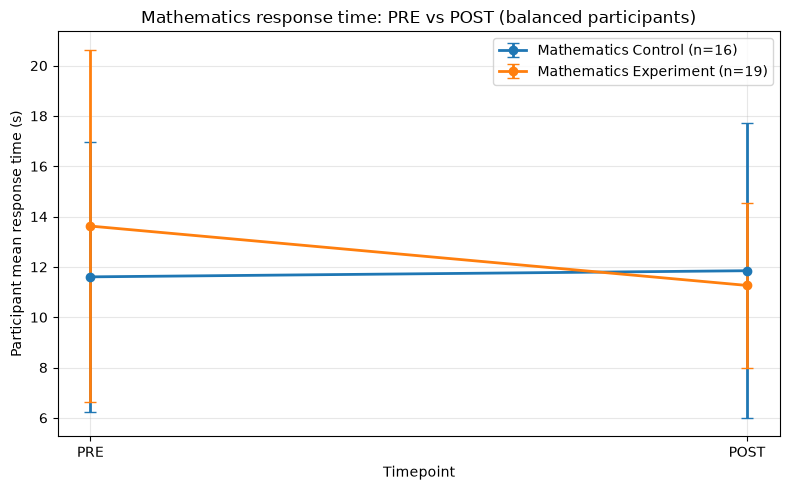

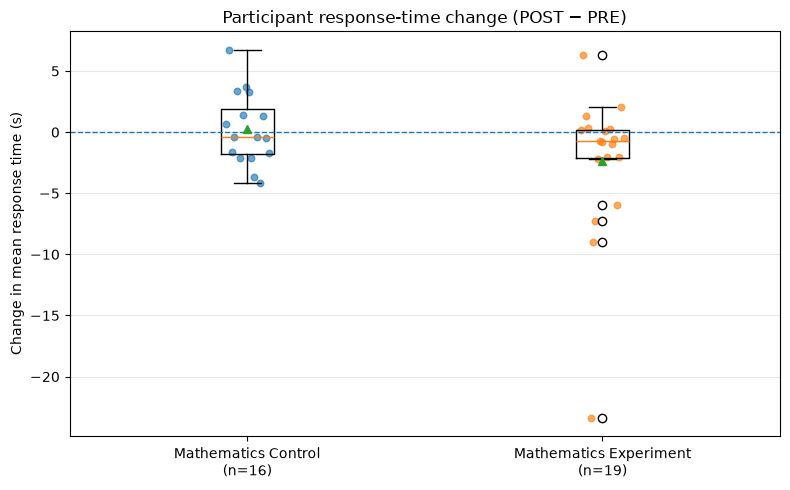

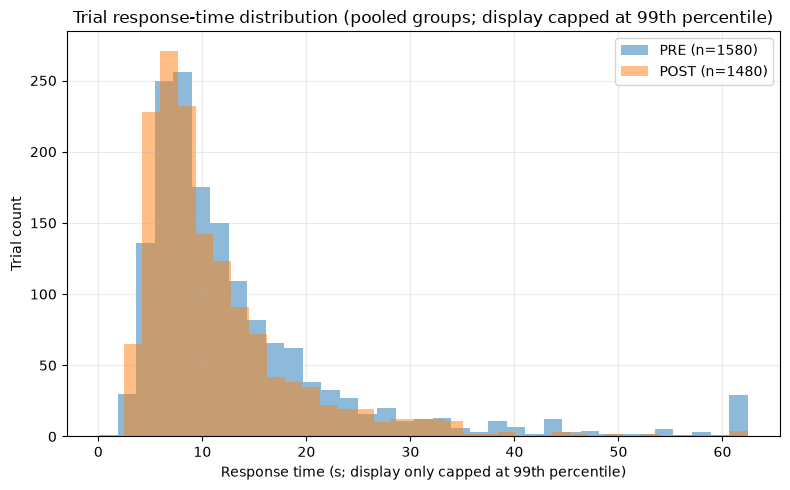

Plots saved to: /Users/ananyosen/Documents/Term Project/analysis/results/events_math_corrected/plots


In [7]:
# Plot 1: group means at PRE and POST with between-participant SD bars.
fig, ax = plt.subplots(figsize=(8, 5))
for group, d in group_summary.groupby("group"):
    d = d.set_index("timepoint").reindex(["PRE", "POST"])
    ax.errorbar(
        ["PRE", "POST"], d["mean_rt_s"], yerr=d["sd_between_subjects_s"],
        marker="o", linewidth=2, capsize=4, label=f"{group} (n={int(d['n_participants'].min())})"
    )
ax.set(title="Mathematics response time: PRE vs POST (balanced participants)",
       xlabel="Timepoint", ylabel="Participant mean response time (s)")
ax.grid(True, alpha=.3); ax.legend()
fig.tight_layout()
fig.savefig(PLOTS_DIR / "01_group_mean_rt_pre_post_balanced.png", dpi=220)
plt.show()

# Plot 2: individual paired changes, grouped correctly.
fig, ax = plt.subplots(figsize=(8, 5))
groups_order = ["Mathematics Control", "Mathematics Experiment"]
plot_data = [primary_wide.loc[primary_wide.group.eq(g), "change_POST_minus_PRE_s"].dropna().values
             for g in groups_order]
labels = [f"{g}\n(n={len(v)})" for g, v in zip(groups_order, plot_data)]
positions = [i + 1 for i, v in enumerate(plot_data) if len(v)]
data_nonempty = [v for v in plot_data if len(v)]
labels_nonempty = [f"{g}\n(n={len(primary_wide.loc[primary_wide.group.eq(g)] )})"
                   for g in groups_order if len(primary_wide.loc[primary_wide.group.eq(g)])]
if data_nonempty:
    ax.boxplot(data_nonempty, tick_labels=labels_nonempty, showmeans=True)
    for i, vals in enumerate(data_nonempty, start=1):
        jitter = np.linspace(-0.06, 0.06, len(vals)) if len(vals) > 1 else [0]
        ax.scatter(np.full(len(vals), i) + jitter, vals, alpha=.65, s=22)
ax.axhline(0, linestyle="--", linewidth=1)
ax.set(title="Participant response-time change (POST − PRE)",
       ylabel="Change in mean response time (s)")
ax.grid(True, axis="y", alpha=.3)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "02_participant_change_by_group_balanced.png", dpi=220)
plt.show()

# Plot 3: pooled trial RT distribution; clipping is visual only, never used for statistics.
cap = valid_pairs["response_time_s"].quantile(.99)
fig, ax = plt.subplots(figsize=(8, 5))
for tp in ["PRE", "POST"]:
    vals = valid_pairs.loc[valid_pairs.timepoint.eq(tp), "response_time_s"]
    if len(vals):
        ax.hist(vals.clip(upper=cap), bins=35, alpha=.5, label=f"{tp} (n={len(vals)})")
ax.set(title="Trial response-time distribution (pooled groups; display capped at 99th percentile)",
       xlabel="Response time (s; display only capped at 99th percentile)", ylabel="Trial count")
ax.legend(); ax.grid(True, alpha=.25)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "03_trial_rt_distribution_pooled.png", dpi=220)
plt.show()

print("Plots saved to:", PLOTS_DIR)

## 7. Final run summary and interpretation checklist

Before using results in a report, check the missing-file audit, block QC, balanced sample sizes, and whether both groups have adequate paired participants. A lower POST−PRE value means faster responses; a positive value means slower responses. Statistical significance does not establish causality by itself.

## 7. Robust response-time analysis: outliers, medians, and activity-specific results

This section is additional to the original mean-based analysis. Extreme observations are **flagged, not automatically deleted**. The IQR and MAD rules are descriptive screening tools; a flagged response is not necessarily an error.

The primary robust comparison uses participant-level medians, with Activity 1 and Activity 2 given equal weight when both are available at both timepoints.

In [8]:
# Flag trial-level extreme response times within each group × timepoint × activity.
# Tukey 1.5×IQR and robust MAD z-score > 3.5 are screening flags only.
def robust_mad_z(values):
    x = pd.to_numeric(values, errors="coerce").astype(float)
    med = np.nanmedian(x)
    mad = np.nanmedian(np.abs(x - med))
    if not np.isfinite(mad) or mad == 0:
        return pd.Series(np.nan, index=values.index)
    return 0.67448975 * (x - med) / mad

outlier_parts = []
for keys, d in valid_pairs.groupby(["subject", "group", "timepoint", "activity"], dropna=False):
    d = d.copy()
    q1, q3 = d["response_time_s"].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower = max(0.0, q1 - 1.5 * iqr)
    upper = q3 + 1.5 * iqr
    d["iqr_lower_bound_s"] = lower
    d["iqr_upper_bound_s"] = upper
    d["flag_iqr"] = (d["response_time_s"] < lower) | (d["response_time_s"] > upper)
    d["robust_mad_z"] = robust_mad_z(d["response_time_s"])
    d["flag_mad"] = d["robust_mad_z"].abs() > 3.5
    d["flag_any_outlier"] = d["flag_iqr"] | d["flag_mad"]
    outlier_parts.append(d)

outlier_audit = pd.concat(outlier_parts, ignore_index=True)
outlier_summary = (outlier_audit.groupby(["group", "timepoint", "activity"], as_index=False)
    .agg(
        n_trials=("response_time_s", "size"),
        median_rt_s=("response_time_s", "median"),
        q1_rt_s=("response_time_s", lambda x: x.quantile(.25)),
        q3_rt_s=("response_time_s", lambda x: x.quantile(.75)),
        min_rt_s=("response_time_s", "min"),
        max_rt_s=("response_time_s", "max"),
        iqr_flagged=("flag_iqr", "sum"),
        mad_flagged=("flag_mad", "sum"),
        any_flagged=("flag_any_outlier", "sum")
    ))

outlier_audit.to_csv(RESULTS_DIR / "math_trial_outlier_flags.csv", index=False)
outlier_summary.to_csv(RESULTS_DIR / "math_trial_outlier_summary.csv", index=False)
display(outlier_summary)
print("Outliers are flagged for review only; no trials have been removed from the main analysis.")

,group,timepoint,activity,n_trials,median_rt_s,q1_rt_s,q3_rt_s,min_rt_s,max_rt_s,iqr_flagged,mad_flagged,any_flagged
0,Mathematics Control,POST,Activity1,360,9.023438,5.820312,14.898437,2.507812,134.976562,18,16,21
1,Mathematics Control,POST,Activity2,360,8.625000,6.335938,12.931641,3.312500,59.531250,19,26,29
2,Mathematics Control,PRE,Activity1,400,9.664063,6.593750,16.742188,0.070313,102.757813,20,14,21
3,Mathematics Control,PRE,Activity2,420,9.828125,7.156250,16.257813,2.500000,161.937500,29,28,37
4,Mathematics Experiment,POST,Activity1,380,9.679688,6.992187,14.281250,2.632812,115.664062,15,13,16
5,Mathematics Experiment,POST,Activity2,380,8.671875,6.421875,12.539063,3.687500,57.187500,24,22,28
6,Mathematics Experiment,PRE,Activity1,380,10.898438,7.388672,15.968750,3.726562,90.039063,18,18,24
7,Mathematics Experiment,PRE,Activity2,380,9.847656,7.181641,14.968750,3.156250,67.875000,16,22,26


Outliers are flagged for review only; no trials have been removed from the main analysis.


### 7A. Median-based participant summaries and PRE–POST tests

For each participant, activity-specific medians are calculated first. The two activity medians are then averaged to give each activity equal weight. The balanced analysis again requires both activities at PRE and POST.

In [9]:
# Participant × activity × timepoint medians, based on positive trial response times.
participant_activity_median = (valid_pairs.groupby(
    ["subject", "group", "timepoint", "activity"], as_index=False
).agg(
    n_trials=("response_time_s", "count"),
    median_rt_s=("response_time_s", "median"),
    mean_rt_s=("response_time_s", "mean")
))

median_timepoint = (participant_activity_median.groupby(
    ["subject", "group", "timepoint"], as_index=False
).agg(
    n_activities=("activity", "nunique"),
    participant_median_rt_s=("median_rt_s", "mean"),
    participant_mean_rt_s=("mean_rt_s", "mean"),
    total_trials=("n_trials", "sum")
))

median_primary = median_timepoint[
    median_timepoint["subject"].isin(eligible_subjects)
].copy()
median_wide = median_primary.pivot(
    index=["subject", "group"], columns="timepoint", values="participant_median_rt_s"
).reset_index().dropna(subset=["PRE", "POST"])
median_wide["change_POST_minus_PRE_s"] = median_wide["POST"] - median_wide["PRE"]

median_group_summary = (median_primary.groupby(["group", "timepoint"], as_index=False)
    .agg(
        n_participants=("subject", "nunique"),
        mean_of_participant_medians_s=("participant_median_rt_s", "mean"),
        median_of_participant_medians_s=("participant_median_rt_s", "median"),
        sd_between_participants_s=("participant_median_rt_s", "std")
    ))
median_change_summary = (median_wide.groupby("group", as_index=False)
    .agg(
        n_paired=("subject", "nunique"),
        mean_change_s=("change_POST_minus_PRE_s", "mean"),
        median_change_s=("change_POST_minus_PRE_s", "median"),
        sd_change_s=("change_POST_minus_PRE_s", "std")
    ))

median_test_rows = []
for group, d in median_wide.groupby("group"):
    delta = d["change_POST_minus_PRE_s"].dropna()
    if len(delta) >= 5 and not np.allclose(delta, 0):
        stat, pval = wilcoxon(delta, alternative="two-sided")
        test_name = "Wilcoxon signed-rank"
    else:
        stat, pval = np.nan, np.nan
        test_name = "Not run: insufficient paired variation"
    median_test_rows.append({
        "comparison": f"Median PRE vs POST within {group}",
        "test": test_name, "n_participants": len(delta),
        "statistic": stat, "p_value": pval,
        "mean_change_s": delta.mean() if len(delta) else np.nan,
        "median_change_s": delta.median() if len(delta) else np.nan
    })

c = median_wide.loc[median_wide.group.eq("Mathematics Control"), "change_POST_minus_PRE_s"].dropna()
e = median_wide.loc[median_wide.group.eq("Mathematics Experiment"), "change_POST_minus_PRE_s"].dropna()
if len(c) >= 2 and len(e) >= 2:
    stat, pval = mannwhitneyu(e, c, alternative="two-sided")
else:
    stat, pval = np.nan, np.nan
median_test_rows.append({
    "comparison": "Median POST−PRE change: Experiment vs Control",
    "test": "Mann–Whitney U" if np.isfinite(pval) else "Not run: insufficient group size",
    "n_participants": len(c) + len(e), "statistic": stat, "p_value": pval,
    "mean_change_s": np.nan, "median_change_s": np.nan
})
median_tests = pd.DataFrame(median_test_rows)

median_primary.to_csv(RESULTS_DIR / "math_participant_timepoint_median_balanced.csv", index=False)
median_wide.to_csv(RESULTS_DIR / "math_participant_prepost_median_change.csv", index=False)
median_group_summary.to_csv(RESULTS_DIR / "math_group_median_rt_summary.csv", index=False)
median_change_summary.to_csv(RESULTS_DIR / "math_group_median_change_summary.csv", index=False)
median_tests.to_csv(RESULTS_DIR / "math_median_response_time_tests.csv", index=False)

display(median_group_summary)
display(median_change_summary)
display(median_tests)

,group,timepoint,n_participants,mean_of_participant_medians_s,median_of_participant_medians_s,sd_between_participants_s
0,Mathematics Control,POST,16,9.924072,8.829102,4.516873
1,Mathematics Control,PRE,16,9.862671,8.910156,3.843706
2,Mathematics Experiment,POST,19,9.642989,9.089844,2.649366
3,Mathematics Experiment,PRE,19,11.638466,10.396484,5.836601


,group,n_paired,mean_change_s,median_change_s,sd_change_s
0,Mathematics Control,16,0.061401,-0.365234,2.389142
1,Mathematics Experiment,19,-1.995477,-0.656250,4.609987


,comparison,test,n_participants,statistic,p_value,mean_change_s,median_change_s
0,Median PRE vs POST within Mathematics Control,Wilcoxon signed-rank,16,68.0,1.000000,0.061401,-0.365234
1,Median PRE vs POST within Mathematics Experiment,Wilcoxon signed-rank,19,38.0,0.020412,-1.995477,-0.656250
2,Median POST−PRE change: Experiment vs Control,Mann–Whitney U,35,114.0,0.214329,NaN,NaN


### 7B. Activity 1 and Activity 2 analysed separately

These comparisons are secondary/exploratory. Each activity is analysed only for participants with that activity recorded at both PRE and POST. The number of participants can therefore differ between activities and groups.

In [10]:
activity_rows = []
activity_test_rows = []
for activity in ["Activity1", "Activity2"]:
    a = participant_activity_median.loc[
        participant_activity_median.activity.eq(activity)
    ].copy()
    w = a.pivot(index=["subject", "group"], columns="timepoint", values="median_rt_s").reset_index()
    if not {"PRE", "POST"}.issubset(w.columns):
        continue
    w = w.dropna(subset=["PRE", "POST"]).copy()
    w["activity"] = activity
    w["change_POST_minus_PRE_s"] = w["POST"] - w["PRE"]
    activity_rows.append(w)

    for group, d in w.groupby("group"):
        delta = d["change_POST_minus_PRE_s"]
        if len(delta) >= 5 and not np.allclose(delta, 0):
            stat, pval = wilcoxon(delta, alternative="two-sided")
            tname = "Wilcoxon signed-rank"
        else:
            stat, pval, tname = np.nan, np.nan, "Not run: insufficient paired variation"
        activity_test_rows.append({
            "activity": activity, "comparison": f"PRE vs POST: {group}",
            "test": tname, "n": len(delta), "statistic": stat, "p_value": pval,
            "mean_change_s": delta.mean() if len(delta) else np.nan,
            "median_change_s": delta.median() if len(delta) else np.nan
        })

    cc = w.loc[w.group.eq("Mathematics Control"), "change_POST_minus_PRE_s"]
    ee = w.loc[w.group.eq("Mathematics Experiment"), "change_POST_minus_PRE_s"]
    if len(cc) >= 2 and len(ee) >= 2:
        stat, pval = mannwhitneyu(ee, cc, alternative="two-sided")
        tname = "Mann–Whitney U"
    else:
        stat, pval, tname = np.nan, np.nan, "Not run: insufficient group size"
    activity_test_rows.append({
        "activity": activity, "comparison": "POST−PRE: Experiment vs Control",
        "test": tname, "n": len(cc) + len(ee), "statistic": stat, "p_value": pval,
        "mean_change_s": np.nan, "median_change_s": np.nan
    })

activity_changes = pd.concat(activity_rows, ignore_index=True) if activity_rows else pd.DataFrame()
activity_tests = pd.DataFrame(activity_test_rows)
activity_changes.to_csv(RESULTS_DIR / "math_activity_specific_median_changes.csv", index=False)
activity_tests.to_csv(RESULTS_DIR / "math_activity_specific_statistical_tests.csv", index=False)
display(activity_changes.groupby(["activity", "group"]).agg(
    n=("subject", "nunique"),
    pre_median_s=("PRE", "median"),
    post_median_s=("POST", "median"),
    median_change_s=("change_POST_minus_PRE_s", "median"),
    mean_change_s=("change_POST_minus_PRE_s", "mean")
).reset_index())
display(activity_tests)

,activity,group,n,pre_median_s,post_median_s,median_change_s,mean_change_s
0,Activity1,Mathematics Control,16,8.781250,8.929687,0.304687,0.197266
1,Activity1,Mathematics Experiment,19,10.570313,9.570312,-0.671875,-1.992599
2,Activity2,Mathematics Control,17,9.421875,8.265625,0.296875,-0.209789
3,Activity2,Mathematics Experiment,19,9.359375,8.703125,-0.937500,-1.998355


,activity,comparison,test,n,statistic,p_value,mean_change_s,median_change_s
0,Activity1,PRE vs POST: Mathematics Control,Wilcoxon signed-rank,16,66.0,0.939880,0.197266,0.304687
1,Activity1,PRE vs POST: Mathematics Experiment,Wilcoxon signed-rank,19,45.0,0.044559,-1.992599,-0.671875
2,Activity1,POST−PRE: Experiment vs Control,Mann–Whitney U,35,115.0,0.226803,NaN,NaN
3,Activity2,PRE vs POST: Mathematics Control,Wilcoxon signed-rank,17,55.0,0.328949,-0.209789,0.296875
4,Activity2,PRE vs POST: Mathematics Experiment,Wilcoxon signed-rank,19,42.0,0.032341,-1.998355,-0.937500
5,Activity2,POST−PRE: Experiment vs Control,Mann–Whitney U,36,135.5,0.419042,NaN,NaN


### 7C. Participant-level bootstrap confidence intervals

95% percentile bootstrap intervals are calculated by resampling participants, not trials. The group-difference interval is Experiment mean change minus Control mean change. Negative values indicate a larger reduction in response time in the Experiment group.

These intervals are descriptive and do not replace the hypothesis tests.

In [11]:
rng = np.random.default_rng(20261116)

def bootstrap_ci(values, statistic=np.mean, n_boot=10000, alpha=.05):
    x = np.asarray(pd.Series(values).dropna(), dtype=float)
    if len(x) < 2:
        return np.nan, np.nan
    draws = rng.choice(x, size=(n_boot, len(x)), replace=True)
    estimates = statistic(draws, axis=1)
    return tuple(np.quantile(estimates, [alpha/2, 1-alpha/2]))

ci_rows = []
for group, d in primary_wide.groupby("group"):
    delta = d["change_POST_minus_PRE_s"].dropna().to_numpy()
    lo_mean, hi_mean = bootstrap_ci(delta, np.mean)
    lo_med, hi_med = bootstrap_ci(delta, np.median)
    ci_rows.append({
        "estimate": f"Mean POST−PRE change: {group}", "n": len(delta),
        "estimate_s": np.mean(delta), "ci95_lower_s": lo_mean, "ci95_upper_s": hi_mean
    })
    ci_rows.append({
        "estimate": f"Median POST−PRE change: {group}", "n": len(delta),
        "estimate_s": np.median(delta), "ci95_lower_s": lo_med, "ci95_upper_s": hi_med
    })

ctrl = primary_wide.loc[primary_wide.group.eq("Mathematics Control"), "change_POST_minus_PRE_s"].dropna().to_numpy()
exp = primary_wide.loc[primary_wide.group.eq("Mathematics Experiment"), "change_POST_minus_PRE_s"].dropna().to_numpy()
if len(ctrl) >= 2 and len(exp) >= 2:
    boot_diff = np.empty(10000)
    for b in range(len(boot_diff)):
        cb = rng.choice(ctrl, size=len(ctrl), replace=True)
        eb = rng.choice(exp, size=len(exp), replace=True)
        boot_diff[b] = eb.mean() - cb.mean()
    ci_rows.append({
        "estimate": "Difference in mean change: Experiment minus Control",
        "n": len(ctrl) + len(exp), "estimate_s": exp.mean() - ctrl.mean(),
        "ci95_lower_s": np.quantile(boot_diff, .025),
        "ci95_upper_s": np.quantile(boot_diff, .975)
    })

bootstrap_results = pd.DataFrame(ci_rows)
bootstrap_results.to_csv(RESULTS_DIR / "math_participant_level_bootstrap_confidence_intervals.csv", index=False)
display(bootstrap_results)

,estimate,n,estimate_s,ci95_lower_s,ci95_upper_s
0,Mean POST−PRE change: Mathematics Control,16,0.243774,-1.142017,1.678837
1,Median POST−PRE change: Mathematics Control,16,-0.386133,-1.724219,1.449023
2,Mean POST−PRE change: Mathematics Experiment,19,-2.359642,-5.369304,-0.069220
3,Median POST−PRE change: Mathematics Experiment,19,-0.717188,-2.039063,0.165625
4,Difference in mean change: Experiment minus Co...,35,-2.603417,-5.913454,0.138455


### 7D. Additional robust plots

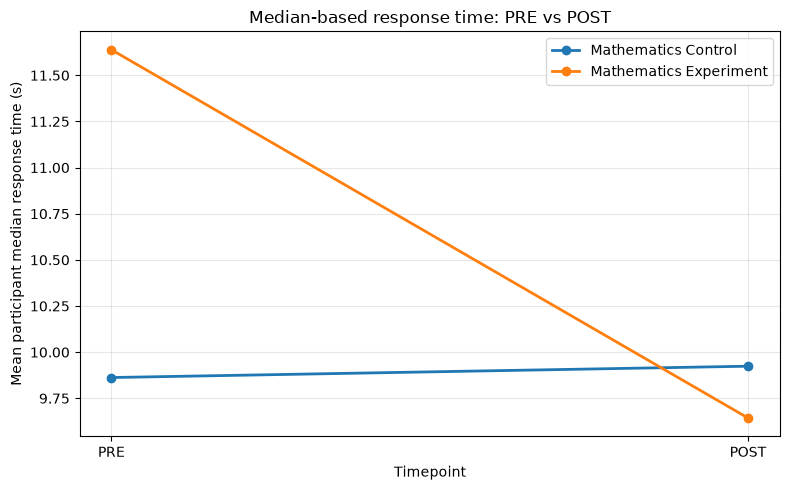

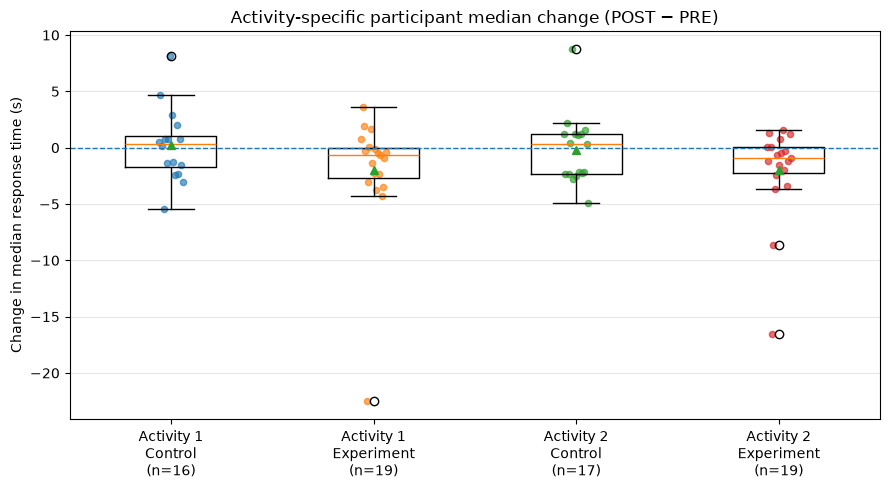

Additional robust-analysis outputs saved to: /Users/ananyosen/Documents/Term Project/analysis/results/events_math_corrected


In [12]:
# Plot 4: participant-level median PRE and POST by group.
fig, ax = plt.subplots(figsize=(8, 5))
for group, d in median_group_summary.groupby("group"):
    d = d.set_index("timepoint").reindex(["PRE", "POST"])
    ax.plot(["PRE", "POST"], d["mean_of_participant_medians_s"],
            marker="o", linewidth=2, label=group)
ax.set(title="Median-based response time: PRE vs POST",
       xlabel="Timepoint", ylabel="Mean participant median response time (s)")
ax.grid(True, alpha=.3); ax.legend()
fig.tight_layout()
fig.savefig(PLOTS_DIR / "04_median_response_time_pre_post.png", dpi=220)
plt.show()

# Plot 5: activity-specific median response-time changes.
if not activity_changes.empty:
    fig, ax = plt.subplots(figsize=(9, 5))
    labels, values = [], []
    for activity in ["Activity1", "Activity2"]:
        for group in ["Mathematics Control", "Mathematics Experiment"]:
            vals = activity_changes.loc[
                activity_changes.activity.eq(activity) & activity_changes.group.eq(group),
                "change_POST_minus_PRE_s"
            ].dropna().to_numpy()
            if len(vals):
                labels.append(f"{activity.replace('Activity', 'Activity ')}\n{group.replace('Mathematics ', '')}\n(n={len(vals)})")
                values.append(vals)
    if values:
        ax.boxplot(values, tick_labels=labels, showmeans=True)
        for i, vals in enumerate(values, start=1):
            jitter = np.linspace(-.06, .06, len(vals)) if len(vals) > 1 else [0]
            ax.scatter(np.full(len(vals), i) + jitter, vals, alpha=.65, s=20)
    ax.axhline(0, linestyle="--", linewidth=1)
    ax.set(title="Activity-specific participant median change (POST − PRE)",
           ylabel="Change in median response time (s)")
    ax.grid(True, axis="y", alpha=.3)
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / "05_activity_specific_median_change.png", dpi=220)
    plt.show()

print("Additional robust-analysis outputs saved to:", RESULTS_DIR)

## 7E. Effect sizes and multiple-comparison adjustment

P-values are not measures of effect magnitude. This section adds participant-level effect sizes and Holm adjustment for the three primary tests and the exploratory activity-specific test family. Within-group effect sizes use paired standardized change (Cohen's dz) and rank-biserial correlation for the Wilcoxon signed-rank test. The between-group effect uses Hedges' g on participant-level change scores. These are descriptive estimates and should be interpreted with their sample sizes and confidence intervals.

In [13]:
from scipy.stats import rankdata

def paired_rank_biserial(delta):
    x = np.asarray(pd.Series(delta).dropna(), dtype=float)
    nz = x[x != 0]
    if len(nz) == 0:
        return np.nan
    ranks = rankdata(np.abs(nz))
    w_pos = ranks[nz > 0].sum()
    w_neg = ranks[nz < 0].sum()
    return (w_pos - w_neg) / (w_pos + w_neg)

def cohens_dz(delta):
    x = np.asarray(pd.Series(delta).dropna(), dtype=float)
    sd = np.std(x, ddof=1) if len(x) > 1 else np.nan
    return np.mean(x) / sd if np.isfinite(sd) and sd > 0 else np.nan

def hedges_g_independent(a, b):
    a = np.asarray(pd.Series(a).dropna(), dtype=float)
    b = np.asarray(pd.Series(b).dropna(), dtype=float)
    if len(a) < 2 or len(b) < 2:
        return np.nan
    sp2 = (((len(a)-1)*np.var(a, ddof=1)) + ((len(b)-1)*np.var(b, ddof=1))) / (len(a)+len(b)-2)
    if sp2 <= 0:
        return np.nan
    d = (np.mean(a)-np.mean(b)) / np.sqrt(sp2)
    df = len(a)+len(b)-2
    correction = 1 - (3/(4*df-1))
    return correction*d

effect_rows = []
for group, d in primary_wide.groupby("group"):
    delta = d["change_POST_minus_PRE_s"]
    effect_rows.append({
        "comparison": f"PRE–POST within {group}",
        "n": len(delta),
        "cohens_dz_POST_minus_PRE": cohens_dz(delta),
        "wilcoxon_rank_biserial": paired_rank_biserial(delta)
    })
effect_rows.append({
    "comparison": "Experiment minus Control change",
    "n": len(control)+len(experiment),
    "cohens_dz_POST_minus_PRE": np.nan,
    "wilcoxon_rank_biserial": np.nan,
    "hedges_g_experiment_minus_control": hedges_g_independent(experiment, control)
})
effect_sizes = pd.DataFrame(effect_rows)
effect_sizes.to_csv(RESULTS_DIR / "math_effect_sizes.csv", index=False)
display(effect_sizes)

# Holm family-wise adjustment for the 3 primary tests (2 within-group + 1 between-group).
def holm_adjust(p_values):
    p = np.asarray(p_values, dtype=float)
    adjusted = np.full(p.shape, np.nan)
    valid_idx = np.where(np.isfinite(p))[0]
    if len(valid_idx) == 0:
        return adjusted
    order = valid_idx[np.argsort(p[valid_idx])]
    m = len(order)
    running = 0.0
    for rank, idx in enumerate(order):
        value = (m-rank) * p[idx]
        running = max(running, value)
        adjusted[idx] = min(running, 1.0)
    return adjusted

primary_stats = stat_results.copy()
primary_stats["p_holm_adjusted"] = holm_adjust(primary_stats["p_value"])
primary_stats.to_csv(RESULTS_DIR / "math_primary_tests_holm_adjusted.csv", index=False)
display(primary_stats)

if "activity_tests" in globals() and not activity_tests.empty:
    activity_tests["p_holm_adjusted"] = holm_adjust(activity_tests["p_value"])
    activity_tests.to_csv(RESULTS_DIR / "math_activity_specific_statistical_tests.csv", index=False)
    display(activity_tests)

,comparison,n,cohens_dz_POST_minus_PRE,wilcoxon_rank_biserial,hedges_g_experiment_minus_control
0,PRE–POST within Mathematics Control,16,0.082588,0.000000,NaN
1,PRE–POST within Mathematics Experiment,19,-0.386660,-0.484211,NaN
2,Experiment minus Control change,35,NaN,NaN,-0.516311


,comparison,test,n_participants,statistic,p_value,mean_change_POST_minus_PRE_s,median_change_POST_minus_PRE_s,p_holm_adjusted
0,PRE vs POST within Mathematics Control,Wilcoxon signed-rank,16,68.0,1.000000,0.243774,-0.386133,1.000000
1,PRE vs POST within Mathematics Experiment,Wilcoxon signed-rank,19,49.0,0.066288,-2.359642,-0.717188,0.198864
2,POST−PRE change: Experiment vs Control,Mann–Whitney U (independent groups),35,113.0,0.202358,NaN,NaN,0.404716


,activity,comparison,test,n,statistic,p_value,mean_change_s,median_change_s,p_holm_adjusted
0,Activity1,PRE vs POST: Mathematics Control,Wilcoxon signed-rank,16,66.0,0.939880,0.197266,0.304687,0.986847
1,Activity1,PRE vs POST: Mathematics Experiment,Wilcoxon signed-rank,19,45.0,0.044559,-1.992599,-0.671875,0.222797
2,Activity1,POST−PRE: Experiment vs Control,Mann–Whitney U,35,115.0,0.226803,NaN,NaN,0.907211
3,Activity2,PRE vs POST: Mathematics Control,Wilcoxon signed-rank,17,55.0,0.328949,-0.209789,0.296875,0.986847
4,Activity2,PRE vs POST: Mathematics Experiment,Wilcoxon signed-rank,19,42.0,0.032341,-1.998355,-0.937500,0.194046
5,Activity2,POST−PRE: Experiment vs Control,Mann–Whitney U,36,135.5,0.419042,NaN,NaN,0.986847


## 7F. Missing-file coverage audit and interpretation checks

This section summarises missing recordings by participant and group. An alternate filename match is not silently treated as a normal exact match: inspect its path and confirm that it is the intended run before accepting it.

In [14]:
coverage_by_subject = (manifest.pivot_table(
    index=["subject", "group"], columns=["timepoint", "activity"],
    values="file_found", aggfunc="max", fill_value=False
).reset_index())
coverage_by_subject.to_csv(RESULTS_DIR / "math_recording_coverage_by_participant.csv", index=False)

missing_by_group = (manifest.loc[~manifest.file_found]
    .groupby("group", as_index=False)
    .agg(missing_recordings=("file_found", "size"),
         affected_participants=("subject", "nunique")))
alternate_matches = manifest.loc[manifest.get("alternate_filename_match", False)].copy()
alternate_matches.to_csv(RESULTS_DIR / "math_alternate_filename_matches_review.csv", index=False)

print("Missing recordings by group:")
display(missing_by_group)
print("Alternate filename matches requiring manual confirmation:")
display(alternate_matches[["subject", "timepoint", "activity", "path"]] if len(alternate_matches) else alternate_matches)

# Explicitly save a compact analysis status report.
status = pd.DataFrame([
    ["Event decoding and pairing", "PASS" if len(audit) and audit.block_qc.eq("PASS").all() else "REVIEW",
     f"{len(audit)} blocks; {len(pairs)} pairs"],
    ["Expected recording coverage", "REVIEW" if (~manifest.file_found).any() else "PASS",
     f"{int(manifest.file_found.sum())}/{len(manifest)} expected event files found"],
    ["Balanced participant analysis", "PASS" if len(primary_wide) > 0 else "FAIL",
     f"{len(primary_wide)} participants: {primary_wide.group.value_counts().to_dict()}"],
    ["Outlier assessment", "COMPLETED — REVIEW FLAGS",
     f"{int(outlier_audit.flag_any_outlier.sum())} trial flags; no automatic exclusions"],
    ["Median analysis", "COMPLETED" if len(median_wide) else "REVIEW",
     f"{len(median_wide)} balanced participants"],
    ["Activity-specific analysis", "COMPLETED" if len(activity_changes) else "REVIEW",
     f"{len(activity_changes)} participant-activity rows"],
    ["Effect sizes and CIs", "COMPLETED" if len(bootstrap_results) else "REVIEW",
     f"{len(bootstrap_results)} bootstrap interval estimates"]
], columns=["analysis_component", "status", "details"])
status.to_csv(RESULTS_DIR / "math_event_analysis_completion_status.csv", index=False)
display(status)

Missing recordings by group:


,group,missing_recordings,affected_participants
0,Mathematics Control,11,6


Alternate filename matches requiring manual confirmation:


,subject,group,session,run,timepoint,activity,expected_path,path,file_found,alternate_filename_match


,analysis_component,status,details
0,Event decoding and pairing,PASS,153 blocks; 3060 pairs
1,Expected recording coverage,REVIEW,153/164 expected event files found
2,Balanced participant analysis,PASS,35 participants: {'Mathematics Experiment': 19...
3,Outlier assessment,COMPLETED — REVIEW FLAGS,202 trial flags; no automatic exclusions
4,Median analysis,COMPLETED,35 balanced participants
5,Activity-specific analysis,COMPLETED,71 participant-activity rows
6,Effect sizes and CIs,COMPLETED,5 bootstrap interval estimates


In [15]:
run_summary = {
    "project_root": str(PROJECT_ROOT),
    "participant_folders": len(subjects),
    "control_participants_found": sum(subject_group(s) == "Mathematics Control" for s in subjects),
    "experiment_participants_found": sum(subject_group(s) == "Mathematics Experiment" for s in subjects),
    "expected_event_files": len(manifest),
    "event_files_found": int(manifest.file_found.sum()),
    "event_files_missing": int((~manifest.file_found).sum()),
    "decoded_event_rows": len(decoded),
    "operation_answer_pairs": len(pairs),
    "positive_response_time_pairs": len(valid_pairs),
    "blocks_pass_qc": int(audit.block_qc.eq("PASS").sum()),
    "blocks_review": int(audit.block_qc.eq("REVIEW").sum()),
    "participants_with_pairs": int(valid_pairs.subject.nunique()),
    "balanced_pre_post_participants": int(primary_wide.subject.nunique()),
    "balanced_control_participants": int(primary_wide.loc[primary_wide.group.eq("Mathematics Control"), "subject"].nunique()),
    "balanced_experiment_participants": int(primary_wide.loc[primary_wide.group.eq("Mathematics Experiment"), "subject"].nunique()),
    "output_directory": str(RESULTS_DIR)
}
display(pd.DataFrame([run_summary]).T.rename(columns={0: "value"}))
pd.DataFrame([run_summary]).to_csv(RESULTS_DIR / "math_event_analysis_run_summary.csv", index=False)

print("\nFINAL CHECKS")
print("- Confirm group labels are only Mathematics Control / Mathematics Experiment.")
print("- Review math_missing_event_files.csv.")
print("- Review every block marked REVIEW in math_event_pairing_audit.csv.")
print("- Use balanced summary and balanced statistical tests for the primary PRE-POST comparison.")
print("- Do not describe selected answer as correctness.")
print("- These are event-response-time results, not EEG band-power results.")

,value
project_root,/Users/ananyosen/Documents/Term Project
participant_folders,41
control_participants_found,22
experiment_participants_found,19
expected_event_files,164
event_files_found,153
event_files_missing,11
decoded_event_rows,6274
operation_answer_pairs,3060
positive_response_time_pairs,3060



FINAL CHECKS
- Confirm group labels are only Mathematics Control / Mathematics Experiment.
- Review math_missing_event_files.csv.
- Review every block marked REVIEW in math_event_pairing_audit.csv.
- Use balanced summary and balanced statistical tests for the primary PRE-POST comparison.
- Do not describe selected answer as correctness.
- These are event-response-time results, not EEG band-power results.


## 7G. Final corrections: median-test Holm adjustment, outlier review export, effect-size intervals, and EEG participant matching

This section closes the remaining analysis/reporting gaps that can be resolved from the available project files. It does **not** invent missing event recordings: absent files remain explicitly unresolved until the original recordings are restored or confirmed unavailable.

In [16]:
# 1) Apply Holm correction to the three median-based primary tests.
median_tests_final = median_tests.copy()
median_tests_final["p_holm_adjusted"] = holm_adjust(median_tests_final["p_value"])
median_tests_final["significant_holm_0_05"] = median_tests_final["p_holm_adjusted"] < 0.05
median_tests_final.to_csv(RESULTS_DIR / "math_median_response_time_tests_holm_adjusted.csv", index=False)
display(median_tests_final)

# 2) Export a focused manual-review list for extreme response times.
# Flags remain screening indicators; no rows are removed from the primary analysis.
outlier_review = outlier_audit.loc[outlier_audit["flag_any_outlier"]].copy()
outlier_review["review_priority"] = np.select(
    [
        outlier_review["response_time_s"] >= outlier_review["response_time_s"].quantile(.99),
        outlier_review["flag_iqr"] & outlier_review["flag_mad"]
    ],
    ["VERY_LONG_OR_EXTREME", "FLAGGED_BY_BOTH_RULES"],
    default="FLAGGED_BY_ONE_RULE"
)
outlier_review = outlier_review.sort_values(
    ["response_time_s"], ascending=False
)
outlier_review.to_csv(RESULTS_DIR / "math_outlier_manual_review_all.csv", index=False)
outlier_review.head(100).to_csv(
    RESULTS_DIR / "math_outlier_manual_review_top100.csv", index=False
)
outlier_by_subject = (outlier_review.groupby(
    ["subject", "group", "timepoint", "activity"], as_index=False
).agg(
    flagged_trials=("response_time_s", "size"),
    maximum_flagged_rt_s=("response_time_s", "max"),
    median_flagged_rt_s=("response_time_s", "median")
))
outlier_by_subject.to_csv(RESULTS_DIR / "math_outlier_flags_by_participant.csv", index=False)
print("Flagged trial rows exported for manual review:", len(outlier_review))
display(outlier_review.head(20)[[
    "subject", "group", "timepoint", "activity", "operation",
    "operation_onset_s", "answer_onset_s", "response_time_s",
    "flag_iqr", "flag_mad", "robust_mad_z"
]])

# 3) Bootstrap confidence intervals for paired Cohen's dz and independent Hedges' g.
# Resampling is performed at participant level.
def bootstrap_paired_dz_ci(delta, n_boot=10000, alpha=.05):
    x = np.asarray(pd.Series(delta).dropna(), dtype=float)
    if len(x) < 3:
        return np.nan, np.nan
    estimates = []
    for _ in range(n_boot):
        xb = rng.choice(x, size=len(x), replace=True)
        sd = np.std(xb, ddof=1)
        if sd > 0:
            estimates.append(np.mean(xb) / sd)
    if len(estimates) < 100:
        return np.nan, np.nan
    return tuple(np.quantile(estimates, [alpha/2, 1-alpha/2]))

def bootstrap_hedges_g_ci(experiment_values, control_values, n_boot=10000, alpha=.05):
    e = np.asarray(pd.Series(experiment_values).dropna(), dtype=float)
    c = np.asarray(pd.Series(control_values).dropna(), dtype=float)
    if len(e) < 3 or len(c) < 3:
        return np.nan, np.nan
    estimates = []
    for _ in range(n_boot):
        eb = rng.choice(e, size=len(e), replace=True)
        cb = rng.choice(c, size=len(c), replace=True)
        g = hedges_g_independent(eb, cb)
        if np.isfinite(g):
            estimates.append(g)
    if len(estimates) < 100:
        return np.nan, np.nan
    return tuple(np.quantile(estimates, [alpha/2, 1-alpha/2]))

effect_ci_rows = []
for group, d in primary_wide.groupby("group"):
    delta = d["change_POST_minus_PRE_s"].dropna()
    lo, hi = bootstrap_paired_dz_ci(delta)
    effect_ci_rows.append({
        "effect": f"Cohen dz: {group}", "n": len(delta),
        "estimate": cohens_dz(delta), "ci95_lower": lo, "ci95_upper": hi
    })
g_lo, g_hi = bootstrap_hedges_g_ci(experiment, control)
effect_ci_rows.append({
    "effect": "Hedges g: Experiment minus Control",
    "n": len(experiment) + len(control),
    "estimate": hedges_g_independent(experiment, control),
    "ci95_lower": g_lo, "ci95_upper": g_hi
})
effect_size_ci = pd.DataFrame(effect_ci_rows)
effect_size_ci.to_csv(RESULTS_DIR / "math_effect_size_confidence_intervals.csv", index=False)
display(effect_size_ci)

# 4) Match event-analysis participants with the whole-recording EEG inventory.
# This checks overlap; it does not imply the two analyses used identical recording subsets.
inventory_candidates = [
    PROJECT_ROOT / "eeg_participant_inventory.csv",
    PROJECT_ROOT / "results" / "eeg_participant_inventory.csv",
    PROJECT_ROOT / "analysis" / "results" / "eeg_participant_inventory.csv"
]
inventory_path = next((x for x in inventory_candidates if x.exists()), None)
if inventory_path is None:
    found = list(PROJECT_ROOT.rglob("eeg_participant_inventory.csv"))
    inventory_path = found[0] if found else None

if inventory_path is not None:
    eeg_inv = pd.read_csv(inventory_path)
    eeg_inv = eeg_inv.loc[
        eeg_inv["task"].astype(str).str.lower().eq("mathematics")
    ].copy()
    eeg_inv["subject_norm"] = eeg_inv["subject_id"].astype(str).str.replace("^sub-", "", regex=True)
    eeg_inv["eeg_valid"] = (
        eeg_inv["processing_status"].astype(str).str.upper().eq("EXTRACTED")
        & pd.to_numeric(eeg_inv["band_power_rows_reported"], errors="coerce").fillna(0).gt(0)
    )
    event_subjects = sorted(valid_pairs["subject"].dropna().unique())
    event_df = pd.DataFrame({"subject": event_subjects})
    event_df["subject_norm"] = event_df["subject"].str.replace("^sub-", "", regex=True)
    match = event_df.merge(
        eeg_inv[["subject_norm", "group", "processing_status", "recordings_loaded",
                 "band_power_rows_reported", "eeg_valid"]],
        on="subject_norm", how="left", suffixes=("_event", "_eeg")
    )
    match["event_has_pairs"] = True
    match["common_valid_subject"] = match["eeg_valid"].fillna(False)
    match.to_csv(RESULTS_DIR / "math_event_vs_whole_recording_participant_match.csv", index=False)
    common = match.loc[match["common_valid_subject"]]
    print("Whole-recording inventory:", inventory_path)
    print("Event participants:", len(event_subjects))
    print("Common participants with valid whole-recording EEG:", len(common))
    display(match.groupby(["group", "eeg_valid"], dropna=False).size().rename("participants").reset_index())
else:
    match = pd.DataFrame()
    print("WARNING: eeg_participant_inventory.csv not found. Participant overlap could not be checked.")
    pd.DataFrame([{"status": "NOT CHECKED", "reason": "EEG participant inventory not found"}]).to_csv(
        RESULTS_DIR / "math_event_vs_whole_recording_participant_match.csv", index=False
    )

# 5) Final coverage disposition: missing event files remain unresolved unless original files are restored.
missing_disposition = missing_files[[
    "subject", "group", "session", "run", "timepoint", "activity", "expected_path"
]].copy()
missing_disposition["status"] = "NOT FOUND — RESTORE OR DOCUMENT UNAVAILABLE"
missing_disposition.to_csv(RESULTS_DIR / "math_missing_recordings_action_list.csv", index=False)
display(missing_disposition)


,comparison,test,n_participants,statistic,p_value,mean_change_s,median_change_s,p_holm_adjusted,significant_holm_0_05
0,Median PRE vs POST within Mathematics Control,Wilcoxon signed-rank,16,68.0,1.000000,0.061401,-0.365234,1.000000,False
1,Median PRE vs POST within Mathematics Experiment,Wilcoxon signed-rank,19,38.0,0.020412,-1.995477,-0.656250,0.061237,False
2,Median POST−PRE change: Experiment vs Control,Mann–Whitney U,35,114.0,0.214329,NaN,NaN,0.428658,False


Flagged trial rows exported for manual review: 202


,subject,group,timepoint,activity,operation,operation_onset_s,answer_onset_s,response_time_s,flag_iqr,flag_mad,robust_mad_z
485,sub-Mc07,Mathematics Control,PRE,Activity2,Operation 23,130.496094,292.433594,161.937500,True,True,40.740040
971,sub-Mc14,Mathematics Control,PRE,Activity2,Operation 37,678.152344,838.808594,160.656250,True,False,2.548455
431,sub-Mc07,Mathematics Control,POST,Activity1,Operation 14,266.371094,401.347656,134.976562,True,True,8.406162
1627,sub-Me02,Mathematics Experiment,POST,Activity1,Operation 12,133.433594,249.097656,115.664062,True,True,7.260004
943,sub-Mc14,Mathematics Control,PRE,Activity1,Operation 12,198.175781,300.933594,102.757813,True,False,2.566932
1907,sub-Me05,Mathematics Experiment,PRE,Activity1,Operation 17,390.394531,480.433594,90.039063,True,False,2.645828
439,sub-Mc07,Mathematics Control,POST,Activity1,Operation 12,547.871094,632.503906,84.632812,True,True,4.665704
1221,sub-Mc18,Mathematics Control,PRE,Activity1,Operation 18,69.363281,148.464844,79.101563,True,True,5.509547
483,sub-Mc07,Mathematics Control,PRE,Activity2,Operation 40,44.589844,115.339844,70.750000,True,True,15.667924
1220,sub-Mc18,Mathematics Control,PRE,Activity1,Operation 17,1.019531,69.339844,68.320312,True,True,4.504368


,effect,n,estimate,ci95_lower,ci95_upper
0,Cohen dz: Mathematics Control,16,0.082588,-0.487173,0.571386
1,Cohen dz: Mathematics Experiment,19,-0.386660,-0.715390,-0.020622
2,Hedges g: Experiment minus Control,35,-0.516311,-1.013726,0.040303


,subject,group,session,run,timepoint,activity,expected_path,status
2,sub-Mc01,Mathematics Control,ses-2,2,POST,Activity1,/Users/ananyosen/Documents/Term Project/sub-Mc...,NOT FOUND — RESTORE OR DOCUMENT UNAVAILABLE
3,sub-Mc01,Mathematics Control,ses-2,3,POST,Activity2,/Users/ananyosen/Documents/Term Project/sub-Mc...,NOT FOUND — RESTORE OR DOCUMENT UNAVAILABLE
8,sub-Mc03,Mathematics Control,ses-1,2,PRE,Activity1,/Users/ananyosen/Documents/Term Project/sub-Mc...,NOT FOUND — RESTORE OR DOCUMENT UNAVAILABLE
30,sub-Mc08,Mathematics Control,ses-2,2,POST,Activity1,/Users/ananyosen/Documents/Term Project/sub-Mc...,NOT FOUND — RESTORE OR DOCUMENT UNAVAILABLE
31,sub-Mc08,Mathematics Control,ses-2,3,POST,Activity2,/Users/ananyosen/Documents/Term Project/sub-Mc...,NOT FOUND — RESTORE OR DOCUMENT UNAVAILABLE
54,sub-Mc14,Mathematics Control,ses-2,2,POST,Activity1,/Users/ananyosen/Documents/Term Project/sub-Mc...,NOT FOUND — RESTORE OR DOCUMENT UNAVAILABLE
55,sub-Mc14,Mathematics Control,ses-2,3,POST,Activity2,/Users/ananyosen/Documents/Term Project/sub-Mc...,NOT FOUND — RESTORE OR DOCUMENT UNAVAILABLE
58,sub-Mc15,Mathematics Control,ses-2,2,POST,Activity1,/Users/ananyosen/Documents/Term Project/sub-Mc...,NOT FOUND — RESTORE OR DOCUMENT UNAVAILABLE
59,sub-Mc15,Mathematics Control,ses-2,3,POST,Activity2,/Users/ananyosen/Documents/Term Project/sub-Mc...,NOT FOUND — RESTORE OR DOCUMENT UNAVAILABLE
84,sub-Mc22,Mathematics Control,ses-1,2,PRE,Activity1,/Users/ananyosen/Documents/Term Project/sub-Mc...,NOT FOUND — RESTORE OR DOCUMENT UNAVAILABLE


## 7H. Final completion checklist and report-ready interpretation

A missing event file cannot be repaired statistically. If the original file is not available, retain the participant/block as missing and report the reduced sample. Do not impute event markers or response times. The event analysis is ready for reporting only with this missingness limitation explicitly stated and the participant-overlap table used when integrating EEG results.

In [17]:
completion_rows = [
    {"item": "Event decoding and operation-answer pairing", "status": "COMPLETE", "evidence": f"{len(audit)} blocks; {len(pairs)} pairs"},
    {"item": "Group identification", "status": "COMPLETE", "evidence": "Control and Experiment labels assigned from subject IDs"},
    {"item": "Balanced mean PRE-POST analysis", "status": "COMPLETE", "evidence": f"{len(primary_wide)} balanced participants"},
    {"item": "Median PRE-POST analysis", "status": "COMPLETE", "evidence": f"{len(median_wide)} balanced participants"},
    {"item": "Median-test Holm correction", "status": "COMPLETE", "evidence": "Three median-based primary tests adjusted"},
    {"item": "Activity-specific comparisons", "status": "COMPLETE", "evidence": f"{len(activity_tests)} activity-specific tests"},
    {"item": "Outlier screening and review export", "status": "COMPLETE — MANUAL REVIEW REQUIRED", "evidence": f"{len(outlier_review)} flagged trials exported"},
    {"item": "Participant-level bootstrap CIs", "status": "COMPLETE", "evidence": f"{len(bootstrap_results)} estimates"},
    {"item": "Effect-size confidence intervals", "status": "COMPLETE", "evidence": f"{len(effect_size_ci)} effect-size intervals"},
    {"item": "EEG participant overlap", "status": "CHECKED" if not match.empty else "NOT CHECKED", "evidence": f"{len(common)} common valid participants" if not match.empty else "Inventory unavailable"},
    {"item": "Missing event recordings", "status": "UNRESOLVED — DATA NOT FOUND", "evidence": f"{len(missing_disposition)} missing expected recordings"},
]
completion_final = pd.DataFrame(completion_rows)
completion_final.to_csv(RESULTS_DIR / "math_event_analysis_final_completion_status.csv", index=False)
display(completion_final)

print("\nFinal interpretation:")
print("- Negative POST−PRE means faster response times at POST.")
print("- Use participant-level observations as the statistical unit.")
print("- Report Holm-adjusted p-values alongside raw p-values.")
print("- Treat flagged extreme responses as requiring review, not automatic exclusion.")
print("- Missing recordings remain missing; do not infer or fabricate their contents.")
print("- Answer 1/2/3 indicates selected option, not correctness.")


,item,status,evidence
0,Event decoding and operation-answer pairing,COMPLETE,153 blocks; 3060 pairs
1,Group identification,COMPLETE,Control and Experiment labels assigned from su...
2,Balanced mean PRE-POST analysis,COMPLETE,35 balanced participants
3,Median PRE-POST analysis,COMPLETE,35 balanced participants
4,Median-test Holm correction,COMPLETE,Three median-based primary tests adjusted
5,Activity-specific comparisons,COMPLETE,6 activity-specific tests
6,Outlier screening and review export,COMPLETE — MANUAL REVIEW REQUIRED,202 flagged trials exported
7,Participant-level bootstrap CIs,COMPLETE,5 estimates
8,Effect-size confidence intervals,COMPLETE,3 effect-size intervals
9,EEG participant overlap,NOT CHECKED,Inventory unavailable



Final interpretation:
- Negative POST−PRE means faster response times at POST.
- Use participant-level observations as the statistical unit.
- Report Holm-adjusted p-values alongside raw p-values.
- Treat flagged extreme responses as requiring review, not automatic exclusion.
- Missing recordings remain missing; do not infer or fabricate their contents.
- Answer 1/2/3 indicates selected option, not correctness.
